# Guidance hyperparameter searches — comparison across targets

Consolidates the six `hyperparameter_search_*` folders that previously sat loose in the
repository, each holding a bare `results.csv` with no analysis attached. The folder
contents now live in `results/hyperparameter_search/<name>/`; this notebook is the
analysis.

All six ran the **same grid** — 10 guidance strengths (eta, 0 to 0.25) x 20 reverse-step
counts (T, 5 to 100), `sigma_r = 1.0` — so they are directly comparable:

| search | target | images |
|---|---|---|
| `axolotl`, `bees` | single out-of-distribution photo | 1 |
| `bedroom`, `bedroom2` | single LSUN-bedroom image (in distribution for the prior) | 1 |
| `indist` | folder of bedroom images | 20 |
| `outdist` | folder of random natural images | 51 |

Two caveats carried through every figure:

* **`bedroom` ran with `seed = 0`; every other search used `seed = 1234`.** Differences
  involving `bedroom` alone mix the target with the seed.
* `outdist` covers 51 images where `indist` covers 20. Comparisons between those two
  average over different numbers of scenes.

These searches predate the LPIPS metric, so only MSE and the final RGC loss are
available — unlike the per-cell-type sweeps under `results/<combination>/`.

Figures use **small multiples rather than six coloured lines**. Six categorical hues
cannot be separated reliably: the best six-way subset of the palette scores a
normal-vision separation of 13.2, below the floor of 15, and 6.0 under simulated
colour-vision deficiency against a target of 8. Faceting removes the problem instead
of hiding it.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

ROOT = Path.cwd()
while not (ROOT / "results").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
SEARCH_DIR = ROOT / "results" / "hyperparameter_search"

SEARCHES = ["bedroom", "bedroom2", "indist", "axolotl", "bees", "outdist"]
LABELS = {"bedroom": "bedroom (seed 0)", "bedroom2": "bedroom2", "indist": "indist (20 imgs)",
          "axolotl": "axolotl", "bees": "bees", "outdist": "outdist (51 imgs)"}

ACCENT, CONTEXT = "#2a78d6", "#c9c8c2"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#dcdbd6"
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 200, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "legend.frameon": False,
})

# Ratios against the unguided baseline are a polarity measure (better / worse than
# no guidance), so they get a diverging map with a neutral midpoint at 1.
RATIO = LinearSegmentedColormap.from_list(
    "ratio", ["#104281", "#2a78d6", "#f0efec", "#e34948", "#8c1d1c"])

tables = {}
for name in SEARCHES:
    df = pd.read_csv(SEARCH_DIR / name / "results.csv")
    if "source_image" not in df.columns:
        df["source_image"] = name          # single-image searches
    tables[name] = df

ETAS = sorted(tables[SEARCHES[0]].eta.unique())
TS = sorted(tables[SEARCHES[0]]["T"].unique())
T_FINAL = max(TS)

# Mean over images, so a single-image and a folder search are handled identically.
grids = {n: d.groupby(["eta", "T"])[["mse", "final_rgc_loss"]].mean().reset_index()
         for n, d in tables.items()}

summary = pd.DataFrame([{
    "search": LABELS[n],
    "images": tables[n].source_image.nunique(),
    "seed": tables[n].seed.unique()[0],
    "etas": tables[n].eta.nunique(),
    "T values": tables[n]["T"].nunique(),
} for n in SEARCHES]).set_index("search")
display(summary)

same_grid = all(sorted(tables[n].eta.unique()) == ETAS and sorted(tables[n]["T"].unique()) == TS
                for n in SEARCHES)
print(f"identical eta x T grid across all six searches: {same_grid}")
print(f"eta: {[round(e, 5) for e in ETAS]}")
print(f"T:   {TS}")

,images,seed,etas,T values
search,,,,
bedroom (seed 0),1,0,10,20
bedroom2,1,1234,10,20
indist (20 imgs),20,1234,10,20
axolotl,1,1234,10,20
bees,1,1234,10,20
outdist (51 imgs),51,1234,10,20


identical eta x T grid across all six searches: True
eta: [np.float64(0.0), np.float64(0.0001), np.float64(0.00027), np.float64(0.00071), np.float64(0.00188), np.float64(0.005), np.float64(0.0133), np.float64(0.03536), np.float64(0.09402), np.float64(0.25)]
T:   [np.int64(5), np.int64(10), np.int64(15), np.int64(20), np.int64(25), np.int64(30), np.int64(35), np.int64(40), np.int64(45), np.int64(50), np.int64(55), np.int64(60), np.int64(65), np.int64(70), np.int64(75), np.int64(80), np.int64(85), np.int64(90), np.int64(95), np.int64(100)]


## 1. Does guidance help, and where?

Each panel is one search, on the same eta x T grid. Colour is **MSE relative to that
search's own unguided run (`eta = 0`) at the same T**, so the panels share a scale even
though the targets have very different absolute error. Blue means guidance beat the
unguided baseline; red means it was worse; the neutral midpoint is "no better than not
guiding at all".

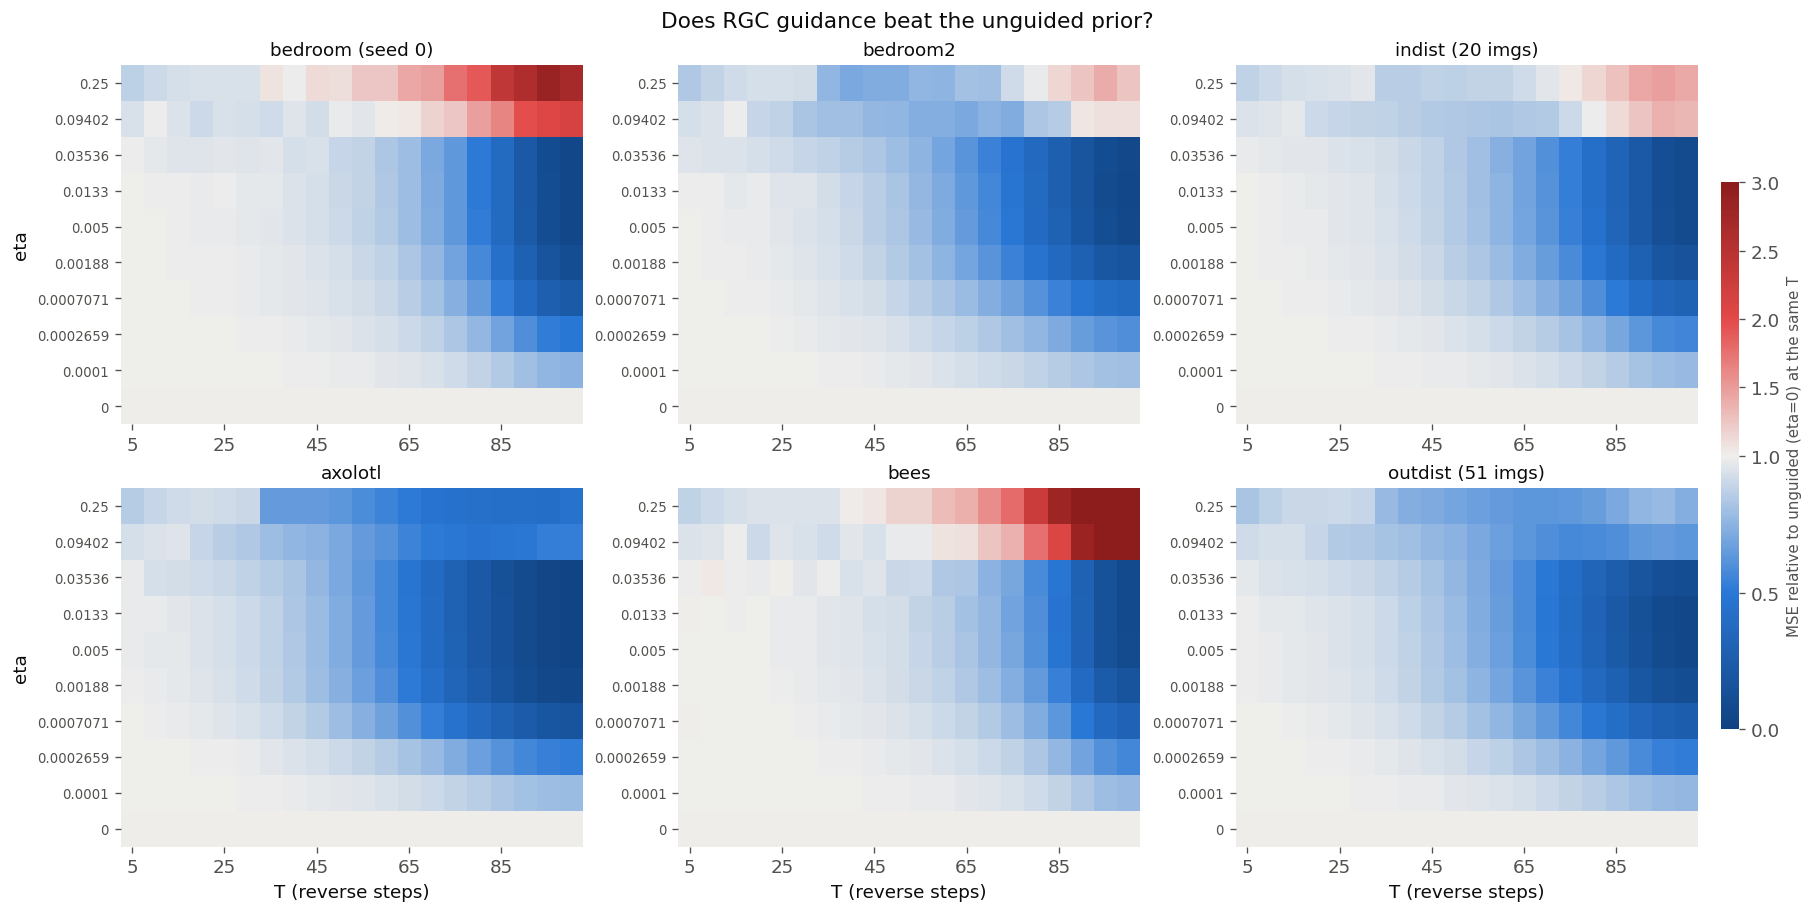

In [2]:
def ratio_grid(name, metric="mse"):
    g = grids[name].pivot(index="eta", columns="T", values=metric)
    return g.div(g.loc[0.0], axis=1)          # against eta=0 at the same T

ratios = {n: ratio_grid(n) for n in SEARCHES}
vmax = max(np.nanmax(r.values) for r in ratios.values())
norm = TwoSlopeNorm(vmin=0, vcenter=1.0, vmax=min(vmax, 3.0))

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), constrained_layout=True)
for ax, name in zip(axes.ravel(), SEARCHES):
    r = ratios[name]
    im = ax.imshow(r.values, cmap=RATIO, norm=norm, aspect="auto", origin="lower")
    ax.set_xticks(range(0, len(TS), 4)); ax.set_xticklabels([TS[i] for i in range(0, len(TS), 4)])
    ax.set_yticks(range(len(ETAS))); ax.set_yticklabels([f"{e:.4g}" for e in ETAS], fontsize=8)
    ax.set_title(LABELS[name], fontsize=11)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("eta")
for ax in axes[-1, :]:
    ax.set_xlabel("T (reverse steps)")

bar = fig.colorbar(im, ax=axes, shrink=0.7, aspect=30, pad=0.015)
bar.set_label("MSE relative to unguided (eta=0) at the same T", fontsize=9, color=INK_2)
bar.outline.set_visible(False)
fig.suptitle("Does RGC guidance beat the unguided prior?", fontsize=13)
plt.show()

## 2. Where is the optimum, target by target?

MSE against eta at the final step count, one panel per search. **The five other
searches are drawn behind in grey**, so each panel carries its own comparison without
asking six colours to stay distinguishable. `eta = 0` is plotted at the left edge as the
unguided reference; the marker shows each search's own best eta.

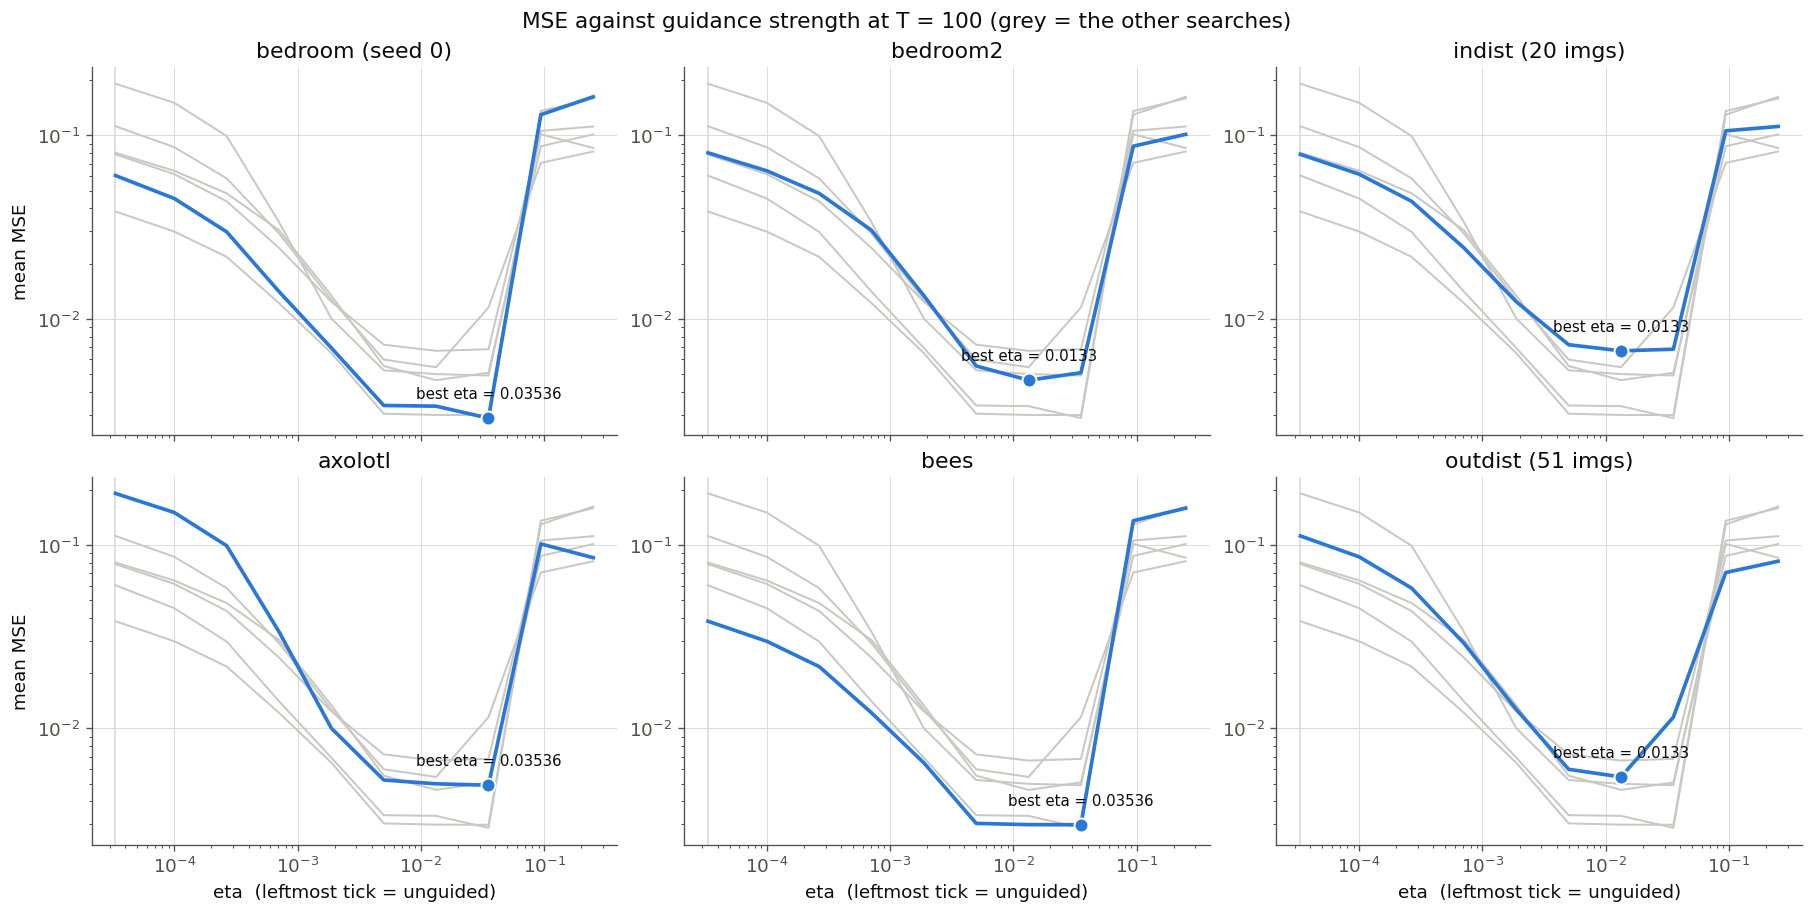

In [3]:
finals = {n: grids[n][grids[n]["T"] == T_FINAL].set_index("eta")["mse"] for n in SEARCHES}
positive = [e for e in ETAS if e > 0]
x_zero = positive[0] / 3          # a finite slot for eta=0 on a log axis
x_of = {e: (x_zero if e == 0 else e) for e in ETAS}
xs = [x_of[e] for e in ETAS]

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), constrained_layout=True, sharex=True)
for ax, name in zip(axes.ravel(), SEARCHES):
    for other in SEARCHES:                      # context first, behind
        if other != name:
            ax.plot(xs, finals[other].reindex(ETAS).values, color=CONTEXT, lw=1.2, zorder=1)
    series = finals[name].reindex(ETAS)
    ax.plot(xs, series.values, color=ACCENT, lw=2.2, zorder=3)
    best = series.idxmin()
    ax.scatter([x_of[best]], [series[best]], s=70, color=ACCENT, zorder=4,
               edgecolor="white", linewidth=1.2)
    ax.annotate(f"best eta = {best:.4g}", xy=(x_of[best], series[best]),
                xytext=(0, 12), textcoords="offset points", ha="center",
                fontsize=9, color=INK)
    ax.set(xscale="log", yscale="log", title=LABELS[name])
    ax.axvline(x_zero, color=GRID, lw=1, zorder=0)
    ax.set_axisbelow(True)
for ax in axes[:, 0]:
    ax.set_ylabel("mean MSE")
for ax in axes[-1, :]:
    ax.set_xlabel("eta  (leftmost tick = unguided)")
fig.suptitle(f"MSE against guidance strength at T = {T_FINAL} (grey = the other searches)",
             fontsize=13)
plt.show()

## 3. Best setting per search

The selected eta and what it bought, relative to not guiding at all.

,best eta,MSE at best eta,MSE unguided,MSE reduction %,best eta rank in grid
search,,,,,
bedroom (seed 0),0.035355,0.00287,0.06038,95.2,8
bedroom2,0.013296,0.00462,0.08036,94.2,7
indist (20 imgs),0.013296,0.00668,0.07877,91.5,7
axolotl,0.035355,0.00490,0.19128,97.4,8
bees,0.035355,0.00298,0.03844,92.2,8
outdist (51 imgs),0.013296,0.00544,0.11213,95.1,7


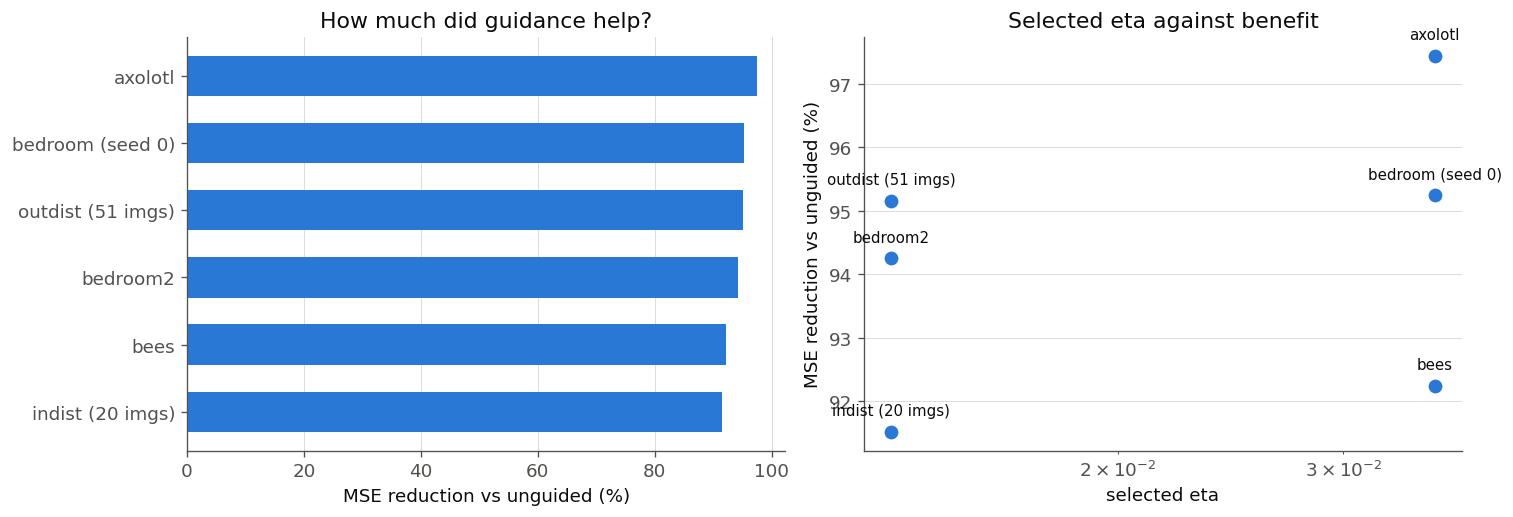

In [4]:
rows = []
for name in SEARCHES:
    s = finals[name].reindex(ETAS)
    best = s.idxmin()
    rows.append({
        "search": LABELS[name],
        "best eta": best,
        "MSE at best eta": s[best],
        "MSE unguided": s[0.0],
        "MSE reduction %": 100 * (1 - s[best] / s[0.0]),
        "best eta rank in grid": ETAS.index(best) + 1,
    })
best_table = pd.DataFrame(rows).set_index("search")
display(best_table.style.format({
    "best eta": "{:.5g}", "MSE at best eta": "{:.5f}",
    "MSE unguided": "{:.5f}", "MSE reduction %": "{:.1f}"}))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), constrained_layout=True)
order = best_table.sort_values("MSE reduction %")
axes[0].barh(order.index, order["MSE reduction %"], color=ACCENT, height=0.6)
axes[0].set(xlabel="MSE reduction vs unguided (%)", title="How much did guidance help?")
axes[0].grid(axis="y", visible=False); axes[0].set_axisbelow(True)

axes[1].scatter(best_table["best eta"], best_table["MSE reduction %"],
                s=90, color=ACCENT, edgecolor="white", linewidth=1.2, zorder=3)
for name, row in best_table.iterrows():
    axes[1].annotate(name, (row["best eta"], row["MSE reduction %"]),
                     xytext=(0, 10), textcoords="offset points", ha="center", fontsize=9)
axes[1].set(xscale="log", xlabel="selected eta", ylabel="MSE reduction vs unguided (%)",
            title="Selected eta against benefit")
axes[1].set_axisbelow(True)
plt.show()

## 4. Reconstruction error against RGC loss as T grows

Each panel traces mean (RGC loss, MSE) as the number of reverse steps increases, at that
search's selected eta, with the other searches behind in grey. A trajectory that drives
RGC loss down while MSE rises is the sampler satisfying the encoder without
reconstructing the image.

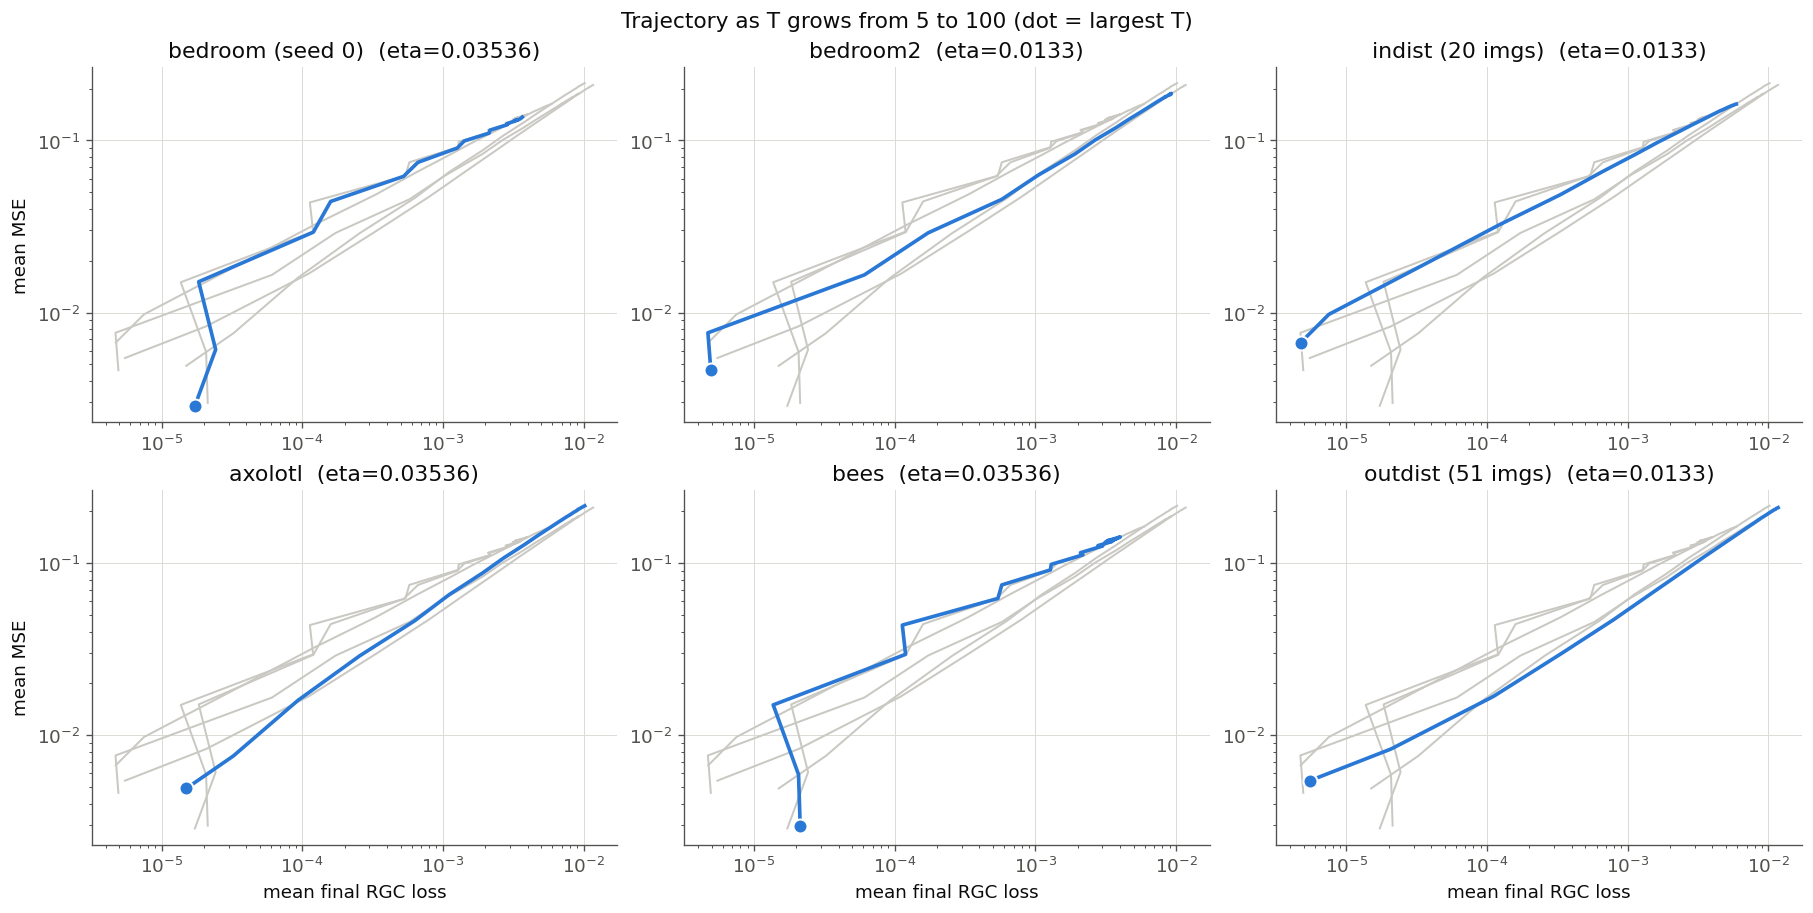

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), constrained_layout=True)
best_eta = {n: finals[n].reindex(ETAS).idxmin() for n in SEARCHES}

def traj(name):
    g = grids[name]
    sub = g[np.isclose(g.eta, best_eta[name])].sort_values("T")
    return sub["final_rgc_loss"].values, sub["mse"].values

for ax, name in zip(axes.ravel(), SEARCHES):
    for other in SEARCHES:
        if other != name:
            x, y = traj(other)
            ax.plot(x, y, color=CONTEXT, lw=1.2, zorder=1)
    x, y = traj(name)
    ax.plot(x, y, color=ACCENT, lw=2.2, zorder=3)
    ax.scatter(x[-1:], y[-1:], s=70, color=ACCENT, zorder=4, edgecolor="white", linewidth=1.2)
    ax.set(xscale="log", yscale="log", title=f"{LABELS[name]}  (eta={best_eta[name]:.4g})")
    ax.set_axisbelow(True)
for ax in axes[:, 0]:
    ax.set_ylabel("mean MSE")
for ax in axes[-1, :]:
    ax.set_xlabel("mean final RGC loss")
fig.suptitle(f"Trajectory as T grows from {min(TS)} to {T_FINAL} (dot = largest T)", fontsize=13)
plt.show()

## 5. The targets

The four single-image searches stored their target alongside the results. `indist` and
`outdist` are folder searches and saved no single target image.

Note that `bedroom.png` and `bedroom2.png` are **WebP files carrying a `.png`
extension**, so `matplotlib.image.imread` cannot decode them. Pillow sniffs the real
container, so it is used here; the loop also tolerates an unreadable target rather than
taking the whole notebook down with it.

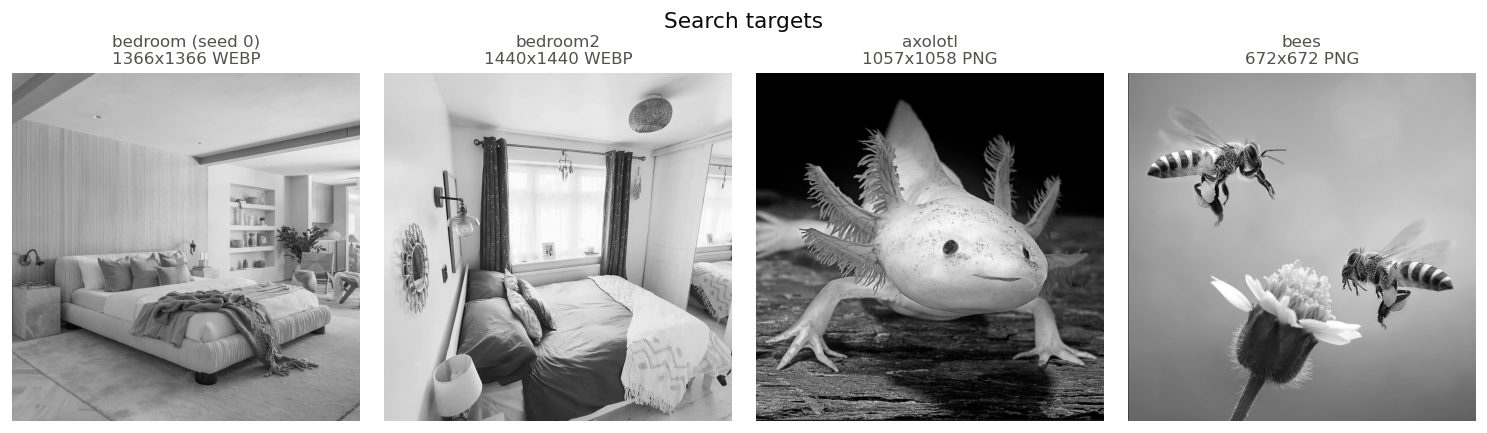

searches with no stored target image: indist, outdist


In [6]:
from PIL import Image

available = [(n, p) for n in SEARCHES for p in sorted(SEARCH_DIR.glob(f"{n}/*.png"))]
loaded = []
for name, path in available:
    try:
        # Pillow identifies the container from its magic bytes, not the extension,
        # which matters because two of these "png" files are actually WebP.
        with Image.open(path) as handle:
            loaded.append((name, path, np.asarray(handle.convert("L")), handle.format))
    except Exception as error:                     # noqa: BLE001 - report and continue
        print(f"could not read {path.name}: {type(error).__name__}: {error}")

if loaded:
    fig, axes = plt.subplots(1, len(loaded), figsize=(3.1 * len(loaded), 3.5),
                             constrained_layout=True)
    for ax, (name, path, image, fmt) in zip(np.atleast_1d(axes), loaded):
        ax.imshow(image, cmap="gray")
        ax.set_title(f"{LABELS[name]}\n{image.shape[1]}x{image.shape[0]} {fmt}",
                     fontsize=10, color=INK_2)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(False)
    fig.suptitle("Search targets", fontsize=13)
    plt.show()

missing = [n for n in SEARCHES if not list(SEARCH_DIR.glob(f"{n}/*.png"))]
print("searches with no stored target image:", ", ".join(missing) or "none")

## Notes

* Panels are faceted rather than overlaid in six colours, because no six-way subset of
  the categorical palette separates reliably (best case: 13.2 normal-vision against a
  floor of 15). Grey context lines preserve the comparison.
* Section 1 normalises each search against its own `eta = 0` column, which is what makes
  targets of very different difficulty comparable on one colour scale.
* `bedroom` used `seed = 0` and everything else `seed = 1234`, so `bedroom` vs
  `bedroom2` is not a clean repeat — it varies seed and image together.
* These searches predate LPIPS; only MSE and RGC loss exist here. The per-cell-type
  sweeps under `results/<combination>/` do carry LPIPS.